# Decision Tree on Iris: Gini vs Entropy

Decision tree classifiers trained with both split criteria, tuned via GridSearchCV and visualized with Graphviz.

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.metrics import accuracy_score, classification_report
import seaborn as sns
import pandas as pd
import graphviz

import matplotlib.pyplot as plt

# Loading the iris dataset
iris = load_iris()
X, y = iris.data, iris.target

# Spliting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Training the Decision Tree Classifier using Information Gain (entropy) and Gini Index
clf_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42)
clf_gini = DecisionTreeClassifier(criterion='gini', random_state=42)

clf_entropy.fit(X_train, y_train)
clf_gini.fit(X_train, y_train)


# Making predictions and evaluate the model
y_pred_entropy = clf_entropy.predict(X_test)
y_pred_gini = clf_gini.predict(X_test)

print("Entropy - Accuracy:", accuracy_score(y_test, y_pred_entropy))
print("Gini - Accuracy:", accuracy_score(y_test, y_pred_gini))

print("Entropy - Classification Report:\n", classification_report(y_test, y_pred_entropy))
print("Gini - Classification Report:\n", classification_report(y_test, y_pred_gini))


Entropy - Accuracy: 0.9777777777777777
Gini - Accuracy: 1.0
Entropy - Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       0.93      1.00      0.96        13
           2       1.00      0.92      0.96        13

    accuracy                           0.98        45
   macro avg       0.98      0.97      0.97        45
weighted avg       0.98      0.98      0.98        45

Gini - Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



In [12]:
# Exporting the resulting decision tree
def export_tree(clf, feature_names, class_names, filename):
    dot_data = export_graphviz(clf, out_file=None, 
                                feature_names=feature_names,  
                                class_names=class_names,  
                                filled=True, rounded=True,  
                                special_characters=True)  
    graph = graphviz.Source(dot_data)  
    graph.format = 'png'
    graph.render(filename)

export_tree(clf_entropy, iris.feature_names, iris.target_names, "decision_tree_entropy")
export_tree(clf_gini, iris.feature_names, iris.target_names, "decision_tree_gini")

Best parameters for Entropy: {'max_depth': 4, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best parameters for Gini: {'max_depth': 4, 'min_samples_leaf': 3, 'min_samples_split': 2}


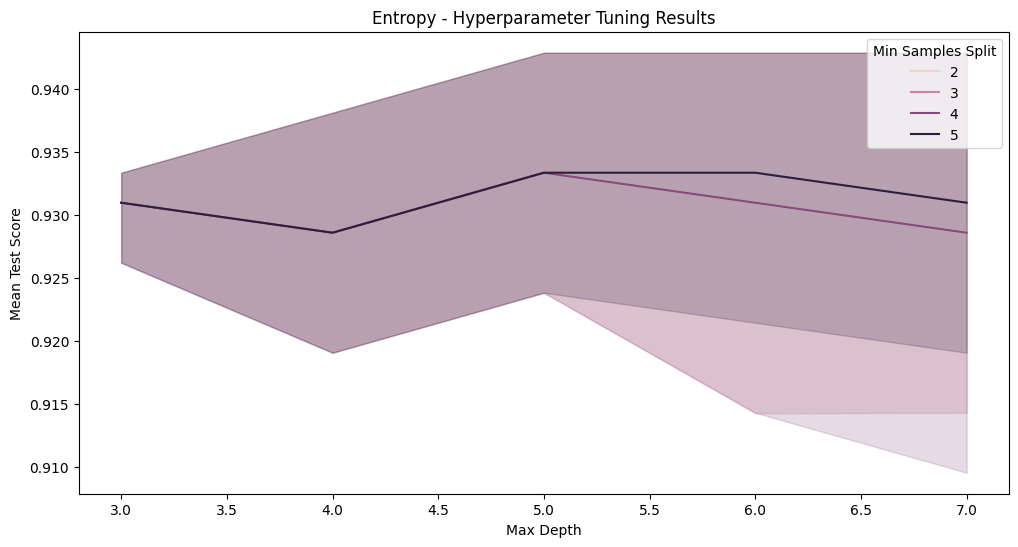

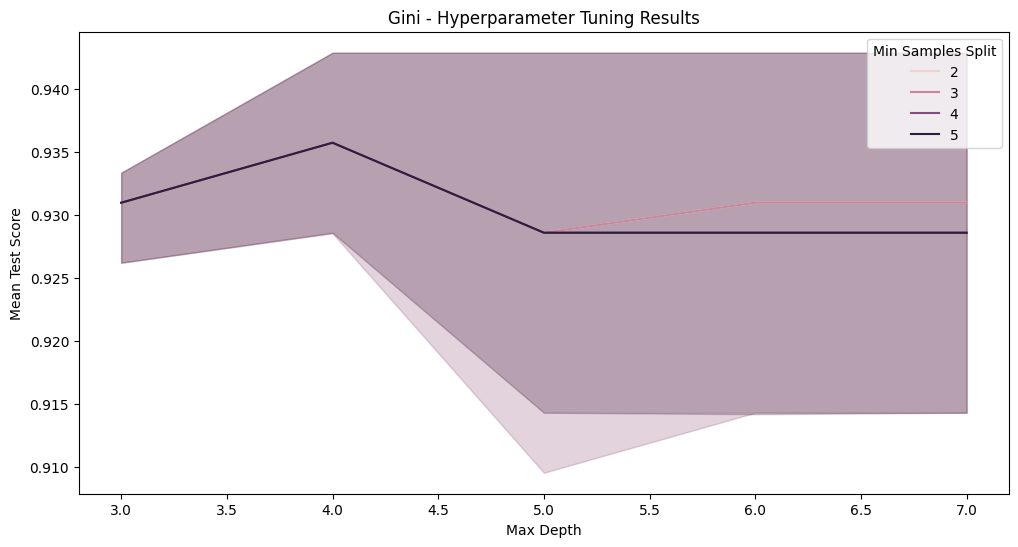

In [5]:

# Applying Hyperparameter tuning
param_grid = {
    'max_depth': [3, 4, 5, 6, 7, None],
    'min_samples_split': [2, 3, 4, 5],
    'min_samples_leaf': [1, 2, 3, 4]
}

# Grid search for both Entropy and Gini
grid_search_entropy = GridSearchCV(DecisionTreeClassifier(criterion='entropy', random_state=42), param_grid, cv=5)
grid_search_gini = GridSearchCV(DecisionTreeClassifier(criterion='gini', random_state=42), param_grid, cv=5)

grid_search_entropy.fit(X_train, y_train)
grid_search_gini.fit(X_train, y_train)

print("Best parameters for Entropy:", grid_search_entropy.best_params_)
print("Best parameters for Gini:", grid_search_gini.best_params_)

# Visualizing the results
results_entropy = pd.DataFrame(grid_search_entropy.cv_results_)
results_gini = pd.DataFrame(grid_search_gini.cv_results_)

plt.figure(figsize=(12, 6))
sns.lineplot(x='param_max_depth', y='mean_test_score', hue='param_min_samples_split', data=results_entropy)
plt.title('Entropy - Hyperparameter Tuning Results')
plt.xlabel('Max Depth')
plt.ylabel('Mean Test Score')
plt.legend(title='Min Samples Split')
plt.show()

plt.figure(figsize=(12, 6))
sns.lineplot(x='param_max_depth', y='mean_test_score', hue='param_min_samples_split', data=results_gini)
plt.title('Gini - Hyperparameter Tuning Results')
plt.xlabel('Max Depth')
plt.ylabel('Mean Test Score')
plt.legend(title='Min Samples Split')
plt.show()